# The cold hand in college golf

**Question.** After a good or bad hole, does the next hole follow?

**Method.** Score every hole as a z-score against the player's own skill and volatility, then
compare real hole order with shuffled hole order.

**Answer.** A blow-up hole carries over to the next hole (cold hand). A great hole does not
(no hot hand).

Everything below is saved to `poster/figures/` as 300-dpi PNG and vector PDF:

| poster box | output |
|---|---|
| Data | `fig1_player_averages`, `fig2_consistency`, `fig3_par_types`, `fig4_d3_vs_pga`, `table1_data` |
| Methods | `eq1_strokes_gained`, `eq2_z_score`, `eq3_momentum`, `fig5_shuffle` |
| Results | `fig6_association`, `fig7_cold_hand`, `table2_par_types`, `table3_results`, `table4_robustness` |

## Setup

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib import font_manager
import warnings
warnings.filterwarnings("ignore", message="There are no gridspecs")   # harmless: table/equation images use their own layout

ROOT      = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
CLEAN_DIR = ROOT / "data" / "clean"
FIG_DIR   = ROOT / "poster" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

FIELD_KEYS = ["tournament_id", "round_number", "layout_id"]
N_HOLES, MIN_FIELD, MIN_ROUNDS = 18, 10, 10
N_SHUFFLE, N_BOOT = 200, 1000
rng = np.random.default_rng(2026)

# PGA Tour 2014, from Elmore & Urbaczewski (2018)
PGA = pd.DataFrame({"avg_to_par": {3: 0.065, 4: 0.051, 5: -0.323},
                    "bob": {3: 0.127, 4: 0.152, 5: 0.385}, "bow": {3: 0.187, 4: 0.205, 5: 0.105}})

# ---- one theme for every figure: seaborn "ticks", one font, reds + greys only ----
installed = {f.name for f in font_manager.fontManager.ttflist}
FONT = "Glacial Indifference" if "Glacial Indifference" in installed else "Times New Roman"
RED, LIGHT_RED, DARK, GRAY, PALE, INK = "#B22A36", "#E59AA1", "#4A4A4A", "#8C8C8C", "#D9D9D9", "#1a1a1a"
PAR_STYLE = {3: dict(color=DARK, ls="-"), 4: dict(color=RED, ls="--"), 5: dict(color=LIGHT_RED, ls=":")}
sns.set_theme(context="talk", style="ticks", font=FONT, rc={
    "figure.constrained_layout.use": True, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#7a7a7a", "axes.linewidth": 1.1, "axes.labelsize": 17, "axes.labelcolor": INK,
    "xtick.labelsize": 15, "ytick.labelsize": 15, "xtick.color": INK, "ytick.color": INK,
    "legend.fontsize": 15, "legend.frameon": False, "mathtext.fontset": "stix", "figure.dpi": 90})

def save(fig, name, title=None):
    "Optional centred title; save as 300-dpi PNG and vector PDF."
    if title:
        fig.suptitle(title, fontsize=21, fontweight="bold", color=INK)
    for ext in ("png", "pdf"):
        fig.savefig(FIG_DIR / f"{name}.{ext}", dpi=300, bbox_inches="tight", facecolor="white")
    plt.show()

def save_table(df, name, title, widths, note=None, bold_rows=()):
    """A publication-style table (thick top and bottom rules, thin rule under the header), saved like a figure.
    `df` holds strings; the first column is left-aligned, the rest right-aligned."""
    n_rows, n_cols = df.shape
    row_h = 0.42
    fig = plt.figure(figsize=(sum(widths), row_h * (n_rows + 2.2) + (0.45 if note else 0.1)), layout="none")
    ax = fig.add_axes([0, 0, 1, 1]); ax.axis("off")
    ax.set_xlim(0, sum(widths)); ax.set_ylim(-(1.0 if note else 0.2), n_rows + 2.2)
    edges = np.r_[0, np.cumsum(widths)]
    def put(r, c, text, bold=False):
        y = n_rows - r - 0.5          # header (r = -1) sits between the top rule and the header rule
        if c == 0:
            ax.text(edges[0] + 0.08, y, text, ha="left", va="center", fontsize=14, fontweight="bold" if bold else "normal")
        else:
            ax.text(edges[c + 1] - 0.08, y, text, ha="right", va="center", fontsize=14, fontweight="bold" if bold else "normal")
    for c, col in enumerate(df.columns):
        put(-1, c, col, bold=True)
    for r in range(n_rows):
        for c in range(n_cols):
            put(r, c, str(df.iat[r, c]), bold=r in bold_rows)
    for y, lw in [(n_rows + 1, 1.8), (n_rows, 0.9), (0, 1.8)]:
        ax.plot([0, sum(widths)], [y, y], color=INK, lw=lw)
    ax.text(sum(widths) / 2, n_rows + 1.65, title, ha="center", va="center", fontsize=17, fontweight="bold")
    if note:
        ax.text(0.08, -0.55, note, ha="left", va="center", fontsize=12, style="italic", color="#444444")
    for ext in ("png", "pdf"):
        fig.savefig(FIG_DIR / f"{name}.{ext}", dpi=300, bbox_inches="tight", facecolor="white")
    plt.show()

def save_equation(name, latex, where, width=9):
    "Render one equation (and a line saying what the symbols are) as a poster-ready image."
    fig = plt.figure(figsize=(width, 1.9), layout="none")
    fig.text(0.5, 0.64, latex, ha="center", va="center", fontsize=30)
    fig.text(0.5, 0.15, where, ha="center", va="center", fontsize=14, color="#444444")
    for ext in ("png", "pdf"):
        fig.savefig(FIG_DIR / f"{name}.{ext}", dpi=300, bbox_inches="tight", facecolor="white")
    plt.show()

sgn = lambda v, d=3: f"{v:+.{d}f}".replace("-", "−")
print("font:", FONT)

font: Times New Roman


## 1. Data

**Source.** Hole-by-hole scores for NCAA Division III golf (Clippd), 2023-24 to 2025-26.
`notebooks/01_cleaning.ipynb` cleans them (60 tests) and keeps or drops every round whole.

**Strokes gained (SG)** on each hole compares a player with everyone else who played that hole
on that course that day (Equation 1 in section 2).

In [2]:
holes = pd.read_parquet(CLEAN_DIR / "d3_clean_holes.parquet")
g = holes.groupby(FIELD_KEYS + ["hole_number"], sort=False, observed=True)["score"]
tot, n = g.transform("sum"), g.transform("size")
holes["sg"] = (tot - holes["score"]) / (n - 1) - holes["score"]
holes["field_avg_all"] = tot / n
assert holes.groupby(FIELD_KEYS + ["hole_number"], observed=True)["sg"].sum().abs().max() < 1e-9

rounds = holes.iloc[::N_HOLES].reset_index(drop=True)
gender, level = rounds["team_gender"].astype(str), rounds["tournament_level"].astype(str)
par6 = (holes["par"].to_numpy().reshape(-1, N_HOLES) == 6).any(axis=1)

# each step of the sample, so Table 1 can report it
audit = pd.read_parquet(CLEAN_DIR / "d3_round_audit.parquet", columns=["team_gender", "tournament_level"])
raw_men_t = int(((audit["team_gender"] == "Men") & (audit["tournament_level"] == "TOURNAMENT")).sum())
steps = [("Men's stroke-play rounds in the raw file", None)]
keep = ((gender == "Men") & (level == "TOURNAMENT")).to_numpy().copy()
steps.append(("Passed all cleaning checks (01_cleaning)", keep.copy()))
keep &= ~rounds["is_match_name"].to_numpy();               steps.append(("Not a dual or match event", keep.copy()))
keep &= (rounds["field_size"] >= MIN_FIELD).to_numpy();    steps.append((f"Field of {MIN_FIELD}+ players on the course", keep.copy()))
keep &= ~par6;                                             steps.append(("Course has only par 3s, 4s and 5s", keep.copy()))
n_per_player = rounds[keep].groupby("player_id").size()
keep &= rounds["player_id"].map(n_per_player).fillna(0).to_numpy() >= MIN_ROUNDS
steps.append((f"Player has {MIN_ROUNDS}+ rounds (final sample)", keep.copy()))

R = rounds[keep].reset_index(drop=True)
mat = lambda col: holes.loc[np.repeat(keep, N_HOLES), col].to_numpy().reshape(-1, N_HOLES)
SG, PAR, TO_PAR, FIELD_AVG = mat("sg"), mat("par"), mat("to_par"), mat("field_avg_all")
PLAYERS, PIDX = np.unique(R["player_id"].to_numpy(), return_inverse=True)
assert np.isin(PAR, [3, 4, 5]).all()

nat = rounds[(gender == "Men") & rounds["tournament_name"].str.contains(r"\bNCAA\b.*National Championship", regex=True)
             & (rounds["round_number"] == 1)]
teams = nat.groupby([nat["season_label"].astype(str), "school_id"]).size().loc[lambda s: s >= 4].index
R["nat_team"] = pd.MultiIndex.from_arrays([R["season_label"].astype(str), R["school_id"]]).isin(teams)
print(f"{len(PLAYERS):,} players | {R['school_id'].nunique()} schools | {len(R):,} rounds | {SG.size:,} holes")

3,401 players | 290 schools | 87,937 rounds | 1,582,866 holes


                                        Step  Rounds Players Schools     Holes
    Men's stroke-play rounds in the raw file 104,468                          
    Passed all cleaning checks (01_cleaning) 102,785   5,766     297 1,850,130
                   Not a dual or match event 100,868   5,711     297 1,815,624
          Field of 10+ players on the course  98,363   5,698     297 1,770,534
           Course has only par 3s, 4s and 5s  98,363   5,698     297 1,770,534
        Player has 10+ rounds (final sample)  87,937   3,401     290 1,582,866
Back-to-back hole pairs analysed (same nine)                         1,406,992


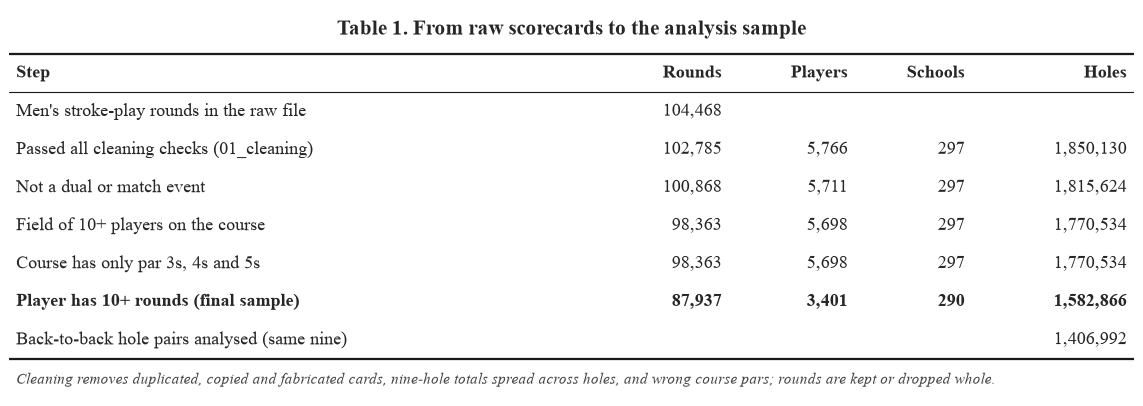

In [3]:
# ---- Table 1: how the data was built ----
rows = []
for label, m in steps:
    if m is None:
        rows.append([label, f"{raw_men_t:,}", "", "", ""])
    else:
        r_ = rounds[m]
        rows.append([label, f"{int(m.sum()):,}", f"{r_['player_id'].nunique():,}", f"{r_['school_id'].nunique():,}",
                     f"{int(m.sum()) * N_HOLES:,}"])
rows.append(["Back-to-back hole pairs analysed (same nine)", "", "", "", f"{len(R) * 16:,}"])
T1 = pd.DataFrame(rows, columns=["Step", "Rounds", "Players", "Schools", "Holes"])
print(T1.to_string(index=False))
save_table(T1, "table1_data", "Table 1. From raw scorecards to the analysis sample", [6.6, 1.4, 1.4, 1.3, 1.8],
           note="Cleaning removes duplicated, copied and fabricated cards, nine-hole totals spread across holes, and wrong course pars; "
                "rounds are kept or dropped whole.", bold_rows=(len(T1) - 2,))

### Figure 1. Players' scoring averages

Each bar counts players by their average round, in strokes over par. The dashed line is the
average player.

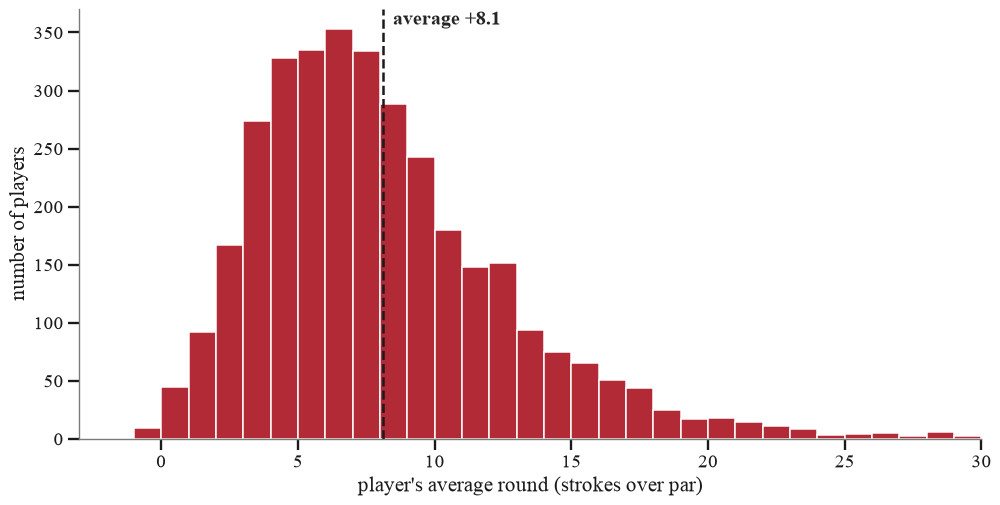

In [4]:
avg = pd.Series(TO_PAR.sum(1)).groupby(PIDX).mean()
fig, ax = plt.subplots(figsize=(11, 5.5))
ax.hist(avg, bins=np.arange(-3, 30.5, 1), color=RED, edgecolor="white", linewidth=1.2)
ax.axvline(avg.mean(), color=INK, lw=2, ls="--")
ax.annotate(f"average {sgn(avg.mean(), 1)}", (avg.mean(), 1), xycoords=("data", "axes fraction"),
            xytext=(8, -2), textcoords="offset points", va="top", fontsize=16, fontweight="bold")
ax.set_xlabel("player's average round (strokes over par)"); ax.set_ylabel("number of players")
ax.set_xlim(-3, 30)
save(fig, "fig1_player_averages")

### Figure 2. Skill and consistency

One dot per player. The x-axis is how many strokes over par they average; the y-axis is how much
their score moves from round to round (standard deviation). The line is a least-squares fit.

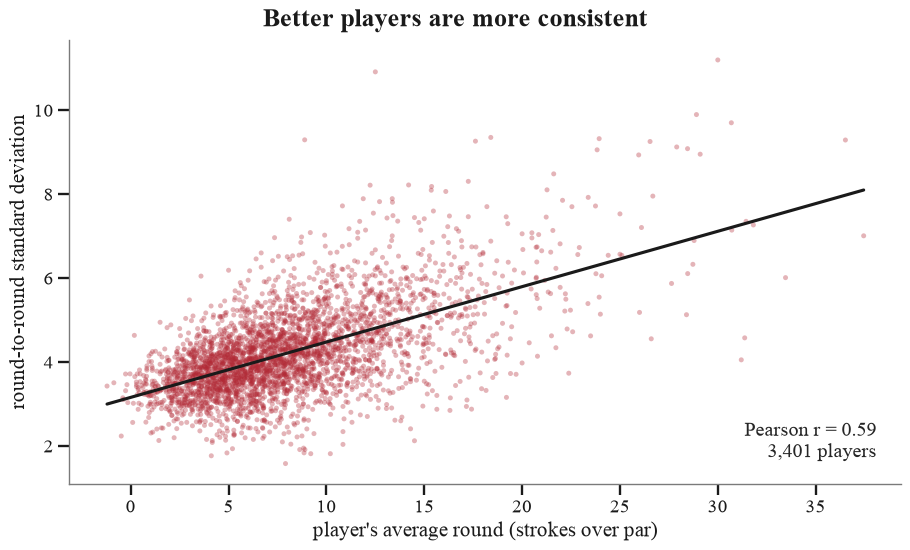

Pearson r = 0.592;  each extra stroke of average adds 0.13 strokes of round-to-round SD


In [5]:
ps = pd.DataFrame({"pid": PIDX, "to_par": TO_PAR.sum(1)}).groupby("pid")["to_par"].agg(["mean", "std"])
r_p = ps["mean"].corr(ps["std"])
fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(ps["mean"], ps["std"], s=16, color=RED, alpha=0.35, edgecolor="none")
b1, b0 = np.polyfit(ps["mean"], ps["std"], 1)
xs = np.linspace(ps["mean"].min(), ps["mean"].max(), 50)
ax.plot(xs, b0 + b1 * xs, color=INK, lw=2.5)
ax.text(0.97, 0.06, f"Pearson r = {r_p:.2f}\n{len(ps):,} players", transform=ax.transAxes, ha="right", fontsize=16)
ax.set_xlabel("player's average round (strokes over par)")
ax.set_ylabel("round-to-round standard deviation")
save(fig, "fig2_consistency", "Better players are more consistent")
print(f"Pearson r = {r_p:.3f};  each extra stroke of average adds {b1:.2f} strokes of round-to-round SD")

### Figure 3. How each par type plays

For every hole on every day: the field's average score minus par. This is the D3 version of
Figure 1 in Elmore & Urbaczewski (2018), with the same line styles (solid = par 3, dashed =
par 4, dotted = par 5).

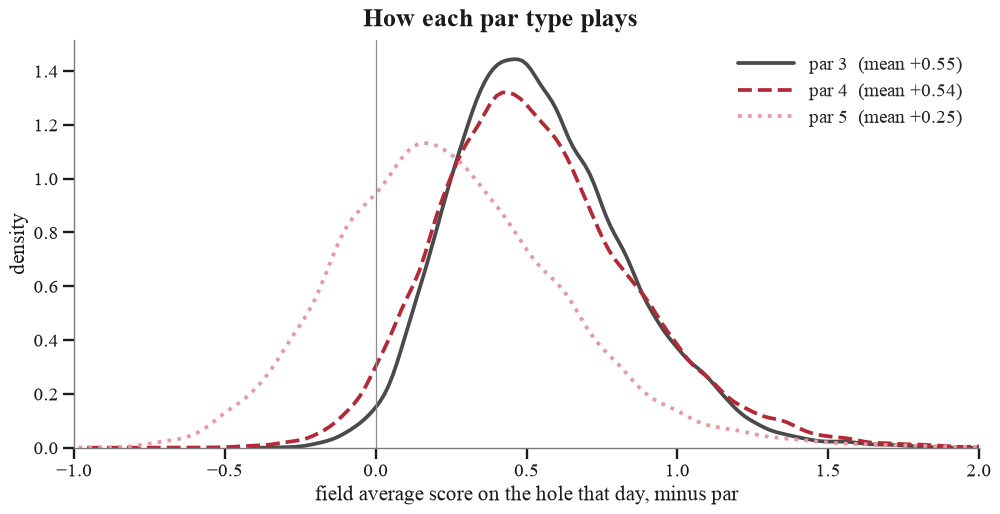

In [6]:
key = R[FIELD_KEYS].astype(str).agg("-".join, axis=1).to_numpy()
fh = pd.DataFrame({"par": PAR.ravel(), "rel": (FIELD_AVG - PAR).ravel(), "key": np.repeat(key, N_HOLES),
                   "hole": np.tile(np.arange(N_HOLES), len(R))}).drop_duplicates(["key", "hole"])
fig, ax = plt.subplots(figsize=(11, 5.6))
for p in (3, 4, 5):
    v = fh.loc[fh["par"] == p, "rel"]
    sns.kdeplot(v, ax=ax, lw=3, bw_adjust=0.8, clip=(-1.5, 3), label=f"par {p}  (mean {sgn(v.mean(), 2)})", **PAR_STYLE[p])
ax.axvline(0, color=GRAY, lw=1)
ax.set_xlim(-1, 2)
ax.set_xlabel("field average score on the hole that day, minus par"); ax.set_ylabel("density")
ax.legend(loc="upper right", handlelength=3)
save(fig, "fig3_par_types", "How each par type plays")

### Figure 4. D3 vs the PGA Tour (optional)

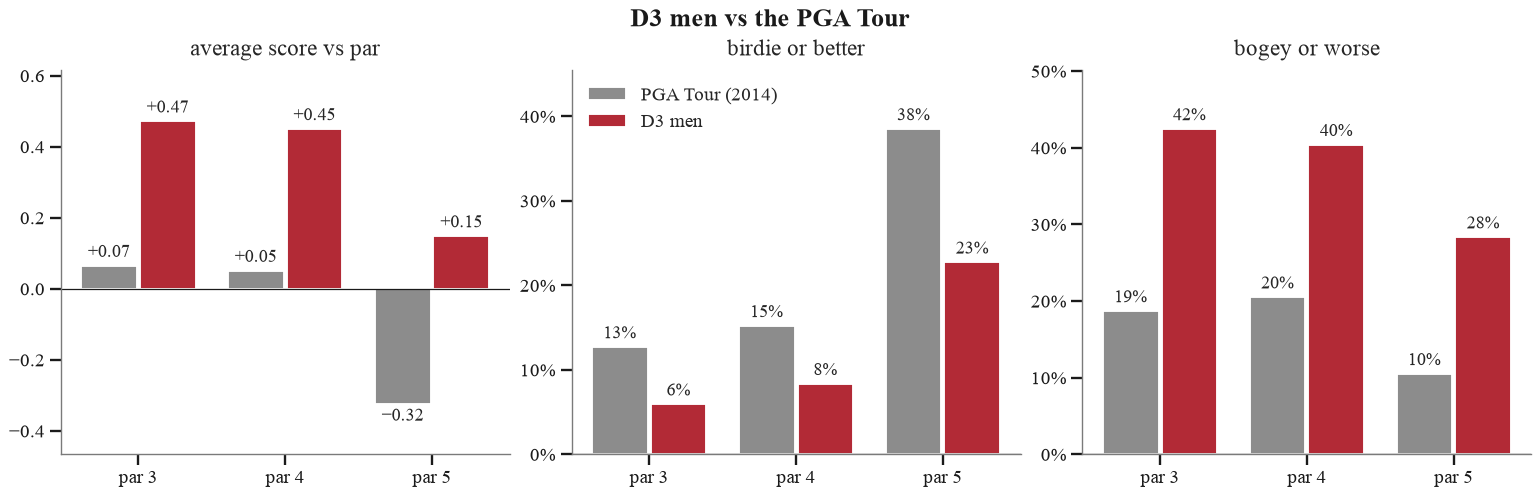

In [7]:
tp, par = TO_PAR.ravel(), PAR.ravel()
D3 = pd.DataFrame({"avg_to_par": pd.Series(tp).groupby(par).mean(),
                   "bob": pd.Series(tp <= -1).groupby(par).mean(), "bow": pd.Series(tp >= 1).groupby(par).mean()})
fig, axes = plt.subplots(1, 3, figsize=(17, 5.4))
for ax, (k, title, f) in zip(axes, [("avg_to_par", "average score vs par", lambda v: sgn(v, 2)),
                                     ("bob", "birdie or better", lambda v: f"{v:.0%}"),
                                     ("bow", "bogey or worse", lambda v: f"{v:.0%}")]):
    x = np.arange(3)
    for off, src, col, lab in [(-0.2, PGA, GRAY, "PGA Tour (2014)"), (0.2, D3, RED, "D3 men")]:
        vals = src.loc[[3, 4, 5], k].to_numpy()
        ax.bar(x + off, vals, 0.38, color=col, edgecolor="white", linewidth=1.5, label=lab)
        for xi, v in zip(x + off, vals):
            ax.annotate(f(v), (xi, v), xytext=(0, 4 if v >= 0 else -4), textcoords="offset points",
                        ha="center", va="bottom" if v >= 0 else "top", fontsize=14)
    ax.axhline(0, color=INK, lw=1)
    ax.set_xticks(x); ax.set_xticklabels(["par 3", "par 4", "par 5"])
    ax.set_title(title, fontsize=18, pad=12); ax.margins(y=0.18)
    if k != "avg_to_par":
        ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
axes[1].legend(loc="upper left")
save(fig, "fig4_d3_vs_pga", "D3 men vs the PGA Tour")

      Par     Holes Mean vs par   SD Birdie or better Bogey or worse PGA Tour mean
    Par 3   364,745       +0.47 0.80             5.9%          42.4%         +0.07
    Par 4   889,136       +0.45 0.87             8.3%          40.4%         +0.05
    Par 5   328,985       +0.15 0.96            22.7%          28.3%         −0.32
All holes 1,582,866       +0.39 0.88            10.8%          38.4%              


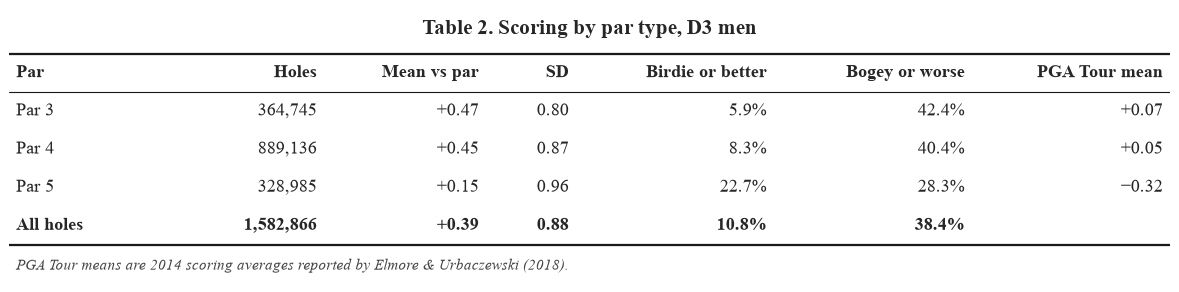

In [8]:
# ---- Table 2: scoring by par type ----
counts = pd.Series(par).value_counts().sort_index()
sd = pd.Series(tp).groupby(par).std()
T2 = pd.DataFrame({
    "Par": ["Par 3", "Par 4", "Par 5", "All holes"],
    "Holes": [f"{counts[p]:,}" for p in (3, 4, 5)] + [f"{len(tp):,}"],
    "Mean vs par": [sgn(D3.loc[p, "avg_to_par"], 2) for p in (3, 4, 5)] + [sgn(tp.mean(), 2)],
    "SD": [f"{sd[p]:.2f}" for p in (3, 4, 5)] + [f"{tp.std():.2f}"],
    "Birdie or better": [f"{D3.loc[p, 'bob']:.1%}" for p in (3, 4, 5)] + [f"{(tp <= -1).mean():.1%}"],
    "Bogey or worse": [f"{D3.loc[p, 'bow']:.1%}" for p in (3, 4, 5)] + [f"{(tp >= 1).mean():.1%}"],
    "PGA Tour mean": [sgn(PGA.loc[p, "avg_to_par"], 2) for p in (3, 4, 5)] + [""]})
print(T2.to_string(index=False))
save_table(T2, "table2_par_types", "Table 2. Scoring by par type, D3 men", [1.7, 1.8, 1.8, 1.0, 2.2, 2.2, 2.2],
           note="PGA Tour means are 2014 scoring averages reported by Elmore & Urbaczewski (2018).", bold_rows=(3,))

## 2. Method

**Step 1. Strokes gained, leave-one-out (Equation 1).** On each hole, a player's score is
compared with the average of **everyone else** on that course that day. Leaving the player out
of their own benchmark matters in college fields: with 12 players, a player's own bogey would
otherwise make the hole look harder and partly explain itself. This removes hole difficulty,
weather and pin positions.

**Step 2. Skill, volatility and the z-score (Equation 2).** For each player and each par type
(3, 4, 5), **skill** μ is their mean SG and **volatility** σ is the standard deviation of their
SG. Both come from the player's *other* rounds, so a hole is never part of its own baseline.
The z-score says how far this hole was from what this player usually does on this type of hole,
in this player's own units. Figure 2 shows why volatility matters: players differ a lot in
consistency.

**Step 3. Pair each hole with the next.** Only pairs inside the same nine are used
(1→2 … 8→9, 10→11 … 17→18). There is no tee-time data, and with 10th-tee starts hole 10 may be
played first.

**Step 4. Shuffle (Equation 3).** Put the holes of each nine in random order and redo step 3,
200 times. The shuffle keeps the player, the day and the holes, and breaks only the order
(Figure 5). Anything still there after shuffling is skill or day form. **Momentum** is what
real order has beyond shuffled order.

**Step 5. Uncertainty.** 95% confidence intervals come from resampling whole players with
replacement, 1,000 times, so a player's holes are never treated as independent.

In [9]:
save_equation("eq1_strokes_gained",
              r"$\mathrm{SG}_{ih} \;=\; \frac{1}{n_h - 1}\sum_{j \neq i} s_{jh} \;-\; s_{ih}$",
              r"$s_{ih}$ = player $i$'s score on hole $h$;  $n_h$ = players on that course that day;  the sum leaves player $i$ out")
save_equation("eq2_z_score",
              r"$z_{ih} \;=\; \frac{\mathrm{SG}_{ih} - \mu_{i,\,p(h)}}{\sigma_{i,\,p(h)}}$",
              r"$\mu$ = player's mean SG (skill) and $\sigma$ = SD of SG (volatility) on par type $p(h)$, from the player's other rounds")
save_equation("eq3_momentum",
              r"$\mathrm{momentum}_k \;=\; \bar{z}_{\,h+1}^{\;\mathrm{real}} \;-\; \bar{z}_{\,h+1}^{\;\mathrm{shuffled}} \quad \mathrm{given}\;\; z_h \in k$",
              r"$k$ = how good hole $h$ was (a z-score bucket);  shuffled = holes in random order within each nine, 200 times", width=11)

<Figure size 810x171 with 0 Axes>

<Figure size 810x171 with 0 Axes>

<Figure size 990x171 with 0 Axes>

In [10]:
Z = np.zeros(SG.shape)
ADJ = np.zeros(SG.shape)            # SG minus skill: the same idea in strokes, for a golfer-friendly size
SKILL_VOL = {}
for p in (3, 4, 5):
    on_p = PAR == p
    x = np.where(on_p, SG, 0.0)
    n_r, s_r, ss_r = on_p.sum(1), x.sum(1), (x ** 2).sum(1)                        # this round
    n_p, s_p, ss_p = (np.bincount(PIDX, v, len(PLAYERS)) for v in (n_r, s_r, ss_r))  # all of the player's rounds
    n_o, s_o, ss_o = n_p[PIDX] - n_r, s_p[PIDX] - s_r, ss_p[PIDX] - ss_r            # the player's OTHER rounds
    mu = s_o / n_o
    sigma = np.sqrt((ss_o - n_o * mu ** 2) / (n_o - 1))
    Z = np.where(on_p, (SG - mu[:, None]) / sigma[:, None], Z)
    ADJ = np.where(on_p, SG - mu[:, None], ADJ)
    SKILL_VOL[p] = pd.DataFrame({"skill": s_p / n_p, "volatility": np.sqrt((ss_p - n_p * (s_p / n_p) ** 2) / (n_p - 1))})

assert np.isfinite(Z).all()
print(f"z: mean {Z.mean():+.3f}, SD {Z.std():.3f}  (about 0 and 1, as a z-score should be)")
print(pd.concat({p: d.describe().loc[["mean", "std"]] for p, d in SKILL_VOL.items()}, axis=1).round(3).to_string())

A = np.array([h for h in range(17) if h != 8])     # hole h ...
B = A + 1                                            # ... and the next hole in the same nine

def shuffle(M):
    "Random order of the holes inside each nine, for every round."
    out = M.copy()
    for s in (slice(0, 9), slice(9, 18)):
        out[:, s] = np.take_along_axis(M[:, s], rng.random(M[:, s].shape).argsort(1), 1)
    return out

z: mean -0.003, SD 1.019  (about 0 and 1, as a z-score should be)
          3                 4                 5           
      skill volatility  skill volatility  skill volatility
mean -0.002      0.768 -0.003      0.836 -0.008      0.902
std   0.182      0.118  0.207      0.113  0.260      0.154


### Figure 5. What the shuffle does

One real nine from the data. **Left:** the order it was played. **Right:** the same nine holes
in a random order. Dark red = worse than this player usually is on that kind of hole; light red =
better. The heights are identical; only the order changes. So the shuffle keeps the player's
day and breaks any link between one hole and the next.

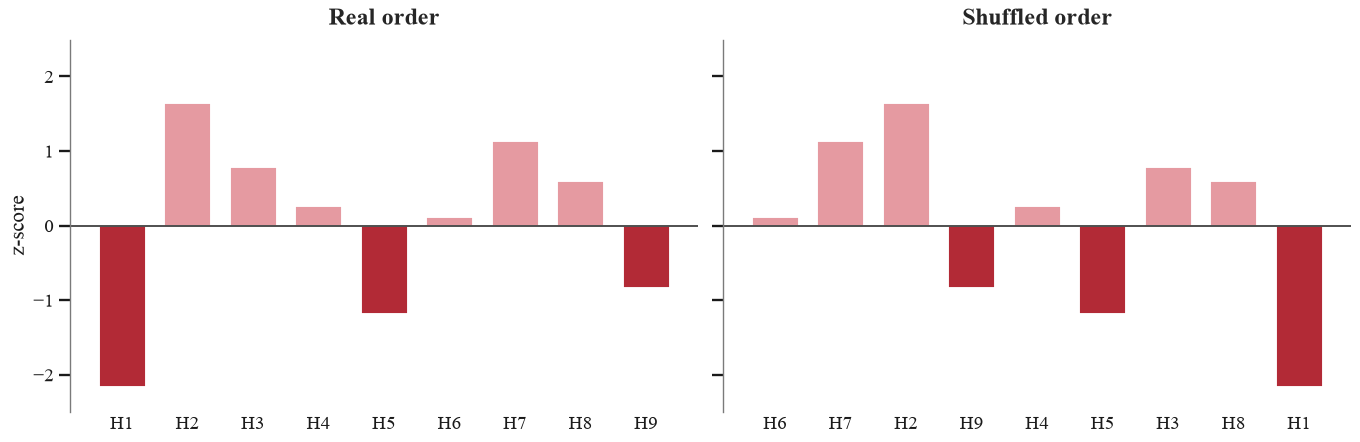

In [11]:
pick = np.random.default_rng(11)
cands = np.flatnonzero((np.abs(Z[:, :9]).max(1) < 2.4) & ((Z[:, :9] < -0.8).sum(1) >= 3) & ((Z[:, :9] > 0.6).sum(1) >= 3))
i = pick.choice(cands)
order = pick.permutation(9)
vals_real, vals_shuf = Z[i, :9], Z[i, :9][order]
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8), sharey=True)
for ax, vals, labels, title in [(axes[0], vals_real, np.arange(1, 10), "Real order"),
                                (axes[1], vals_shuf, order + 1, "Shuffled order")]:
    ax.bar(np.arange(9), vals, color=np.where(vals < 0, RED, LIGHT_RED), width=0.72)
    ax.axhline(0, color=INK, lw=1.2)
    ax.set_xticks(np.arange(9)); ax.set_xticklabels([f"H{h}" for h in labels])
    ax.set_title(title, fontsize=19, fontweight="bold", pad=12)
    ax.spines["bottom"].set_visible(False); ax.tick_params(axis="x", length=0)
axes[0].set_ylabel("z-score")
lim = np.abs(vals_real).max() * 1.15
axes[0].set_ylim(-lim, lim)
save(fig, "fig5_shuffle")

## 3. Results

Bucket every hole by its z-score, then average the z-score of the **next** hole, in real order
and in shuffled order.

In [12]:
EDGES = [-2, -1, -0.5, 0.5, 1, 2]
BUCKETS = ["≤ −2", "−2 to −1", "−1 to −0.5", "−0.5 to 0.5", "0.5 to 1", "1 to 2", "≥ 2"]
NAMES = ["blow-up", "bad", "slightly bad", "normal", "slightly good", "good", "great"]

def bucket_sums(Mx, My=None):
    "Per round: count and sum of next-hole values, by bucket of this-hole z."
    My = Mx if My is None else My
    k = np.digitize(Mx[:, A], EDGES)
    rows = np.repeat(np.arange(len(Mx)), len(A))
    cnt, tot = np.zeros((len(Mx), 7)), np.zeros((len(Mx), 7))
    np.add.at(cnt, (rows, k.ravel()), 1); np.add.at(tot, (rows, k.ravel()), My[:, B].ravel())
    return cnt, tot

def momentum(rows=None, n_shuffle=N_SHUFFLE, n_boot=N_BOOT):
    "Real vs shuffled next-hole z by bucket, with a player-resampling 95% interval and a shuffle p-value."
    Zs = Z if rows is None else Z[rows]
    pid = PIDX if rows is None else np.unique(PIDX[rows], return_inverse=True)[1]
    npl = pid.max() + 1
    cnt, tot = bucket_sums(Zs)
    real = tot.sum(0) / cnt.sum(0)
    runs = np.array([(lambda c, t: t.sum(0) / c.sum(0))(*bucket_sums(shuffle(Zs))) for _ in range(n_shuffle)])
    shuf = runs.mean(0)
    Pc, Pt = np.zeros((npl, 7)), np.zeros((npl, 7))
    np.add.at(Pc, pid, cnt); np.add.at(Pt, pid, tot)
    W = np.stack([np.bincount(rng.integers(0, npl, npl), minlength=npl) for _ in range(n_boot)])
    lo, hi = np.percentile((W @ Pt) / (W @ Pc) - shuf, [2.5, 97.5], axis=0)
    p = np.array([(1 + (np.abs(runs[:, j] - shuf[j]) >= abs(real[j] - shuf[j])).sum()) / (1 + n_shuffle) for j in range(7)])
    return pd.DataFrame({"pairs": cnt.sum(0).astype(int), "real": real, "shuffled": shuf, "momentum": real - shuf,
                         "lo": lo, "hi": hi, "p": p}, index=BUCKETS)

RES = momentum()
print(RES.round(4).to_string())

              pairs    real  shuffled  momentum      lo      hi       p
≤ −2          54881 -0.0951   -0.0773   -0.0179 -0.0270 -0.0087  0.0050
−2 to −1     151321 -0.0574   -0.0536   -0.0038 -0.0092  0.0017  0.0995
−1 to −0.5   187566 -0.0303   -0.0264   -0.0040 -0.0081  0.0002  0.0896
−0.5 to 0.5  570241 -0.0061   -0.0090    0.0029  0.0008  0.0050  0.0100
0.5 to 1     268624  0.0353    0.0344    0.0009 -0.0026  0.0044  0.5920
1 to 2       155885  0.0521    0.0482    0.0040 -0.0014  0.0089  0.0597
≥ 2           18474  0.0721    0.0886   -0.0165 -0.0307 -0.0008  0.0199


In [13]:
# the same comparison in strokes: shuffle Z and ADJ together so each hole keeps both values
def shuffle_pair(M1, M2):
    out1, out2 = M1.copy(), M2.copy()
    for s in (slice(0, 9), slice(9, 18)):
        ix = rng.random(M1[:, s].shape).argsort(1)
        out1[:, s] = np.take_along_axis(M1[:, s], ix, 1); out2[:, s] = np.take_along_axis(M2[:, s], ix, 1)
    return out1, out2
c_s, t_s = bucket_sums(Z, ADJ)
real_s = t_s.sum(0) / c_s.sum(0)
shuf_s = np.mean([(lambda c, t: t.sum(0) / c.sum(0))(*bucket_sums(*shuffle_pair(Z, ADJ))) for _ in range(100)], 0)
RES["momentum (strokes)"] = real_s - shuf_s
print(RES[["momentum", "momentum (strokes)"]].round(4).to_string())

             momentum  momentum (strokes)
≤ −2          -0.0179             -0.0154
−2 to −1      -0.0038             -0.0035
−1 to −0.5    -0.0040             -0.0029
−0.5 to 0.5    0.0029              0.0024
0.5 to 1       0.0009              0.0006
1 to 2         0.0040              0.0037
≥ 2           -0.0165             -0.0126


### Figure 6. Good holes follow good holes, but mostly because of the day

**How to read it.** Red bars: after a hole of each kind (x-axis), how the **next** hole went
(y-axis, z-score), in the order the holes were really played. Grey bars: the same, with the
holes shuffled within each nine.

* The red staircase is the raw pattern: good holes are followed by good holes, bad by bad.
* The grey bars are almost as tall. Even when the "next" hole is a random hole from the same
  nine, the pattern stays. So most of it comes from the player's **day**, not from the
  previous hole.
* Momentum is only the gap between red and grey (Figure 7).

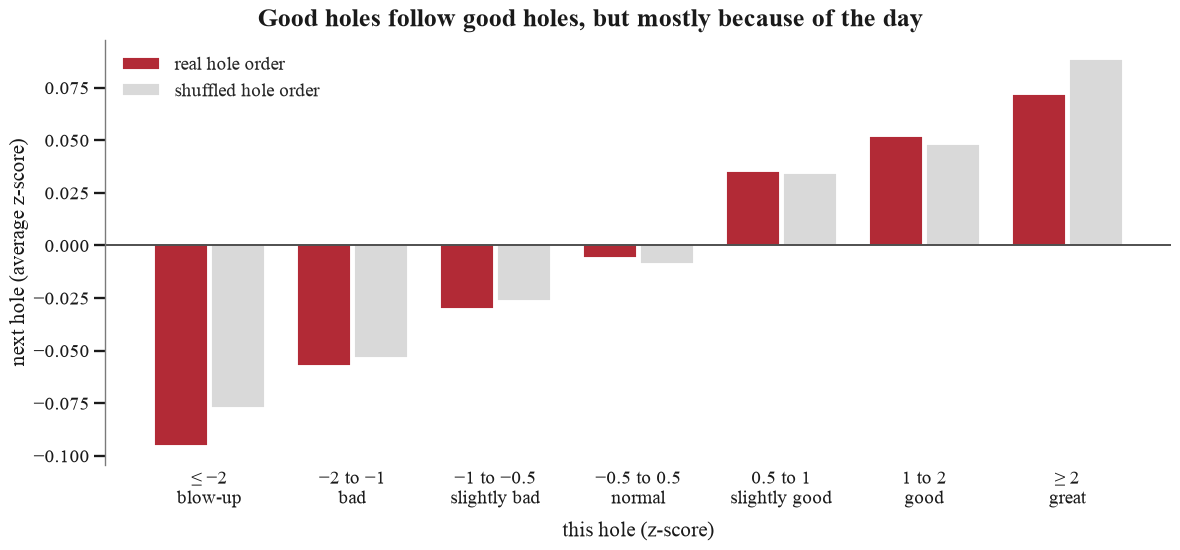

In [14]:
x = np.arange(7)
fig, ax = plt.subplots(figsize=(13, 6))
ax.bar(x - 0.2, RES["real"], 0.38, color=RED, label="real hole order")
ax.bar(x + 0.2, RES["shuffled"], 0.38, color=PALE, label="shuffled hole order")
ax.axhline(0, color=INK, lw=1.2)
ax.set_xticks(x); ax.set_xticklabels([f"{b}\n{nm}" for b, nm in zip(BUCKETS, NAMES)])
ax.spines["bottom"].set_visible(False); ax.tick_params(axis="x", length=0)
ax.set_xlabel("this hole (z-score)", labelpad=10); ax.set_ylabel("next hole (average z-score)")
ax.legend(loc="upper left")
save(fig, "fig6_association", "Good holes follow good holes, but mostly because of the day")

### Figure 7. The cold hand

**How to read it.** Each dot is **momentum**: how much better (above 0) or worse (below 0) the
next hole was in real order than in shuffled order, in the player's own standard deviations.
It is the gap between the red and grey bars in Figure 6.

**What the whiskers (95% confidence intervals) mean.**
* We don't measure every college golfer who will ever play, only these 3,401. If a different
  set of players had been in the data, the estimate would move a little. The interval shows how
  much.
* It is built by redrawing the 3,401 players at random with replacement, 1,000 times, and
  recomputing momentum each time. The middle 95% of those 1,000 answers is the interval.
* **Interval entirely below 0:** the next hole really is worse; chance alone would very rarely
  produce this. **Interval crossing 0:** we can't tell the effect apart from zero.
* So: the dot is the best guess, the whisker is the range of plausible values, and the colour
  says whether that range excludes zero.

**Reading this result.** After a blow-up hole (z ≤ −2), the dot sits below zero and the whole
interval is below zero: a **cold hand**. After a great hole (z ≥ 2) there is no boost; the
estimate is also slightly negative. There is **no hot hand**.

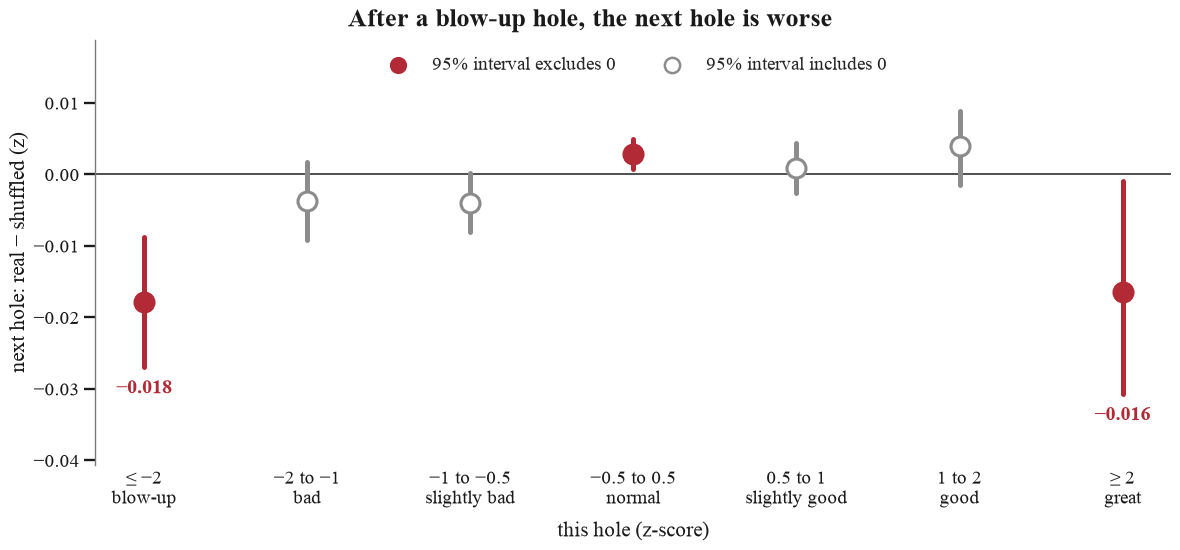

In [15]:
sig = (RES["hi"] < 0) | (RES["lo"] > 0)
fig, ax = plt.subplots(figsize=(13, 6))
ax.axhline(0, color=INK, lw=1.2)
for xi, (b, r_), s in zip(x, RES.iterrows(), sig):
    c = RED if s else GRAY
    ax.plot([xi, xi], [r_["lo"], r_["hi"]], color=c, lw=4, solid_capstyle="round")
    ax.scatter(xi, r_["momentum"], s=230, color=c if s else "white", edgecolor=c, linewidth=2.5, zorder=3)
for j in (0, 6):
    ax.annotate(f"{sgn(RES['momentum'].iloc[j])}", (x[j], RES["lo"].iloc[j]), xytext=(0, -10), textcoords="offset points",
                ha="center", va="top", fontsize=16, fontweight="bold", color=RED if sig.iloc[j] else GRAY)
ax.set_xticks(x); ax.set_xticklabels([f"{b}\n{nm}" for b, nm in zip(BUCKETS, NAMES)])
ax.spines["bottom"].set_visible(False); ax.tick_params(axis="x", length=0)
ax.set_xlabel("this hole (z-score)", labelpad=10)
ax.set_ylabel("next hole: real − shuffled (z)")
ax.margins(y=0.25)
ax.scatter([], [], s=150, color=RED, label="95% interval excludes 0")
ax.scatter([], [], s=150, color="white", edgecolor=GRAY, linewidth=2, label="95% interval includes 0")
ax.legend(loc="upper center", ncol=2, bbox_to_anchor=(0.5, 1.0))
save(fig, "fig7_cold_hand", "After a blow-up hole, the next hole is worse")

             This hole (z)   Pairs Next hole, real Next hole, shuffled Momentum           95% CI     p Strokes
           ≤ −2  (blow-up)  54,881          −0.095              −0.077   −0.018 −0.027 to −0.009 0.005  −0.015
           −2 to −1  (bad) 151,321          −0.057              −0.054   −0.004 −0.009 to +0.002 0.100  −0.003
−1 to −0.5  (slightly bad) 187,566          −0.030              −0.026   −0.004 −0.008 to +0.000 0.090  −0.003
     −0.5 to 0.5  (normal) 570,241          −0.006              −0.009   +0.003 +0.001 to +0.005 0.010  +0.002
 0.5 to 1  (slightly good) 268,624          +0.035              +0.034   +0.001 −0.003 to +0.004 0.592  +0.001
            1 to 2  (good) 155,885          +0.052              +0.048   +0.004 −0.001 to +0.009 0.060  +0.004
              ≥ 2  (great)  18,474          +0.072              +0.089   −0.016 −0.031 to −0.001 0.020  −0.013


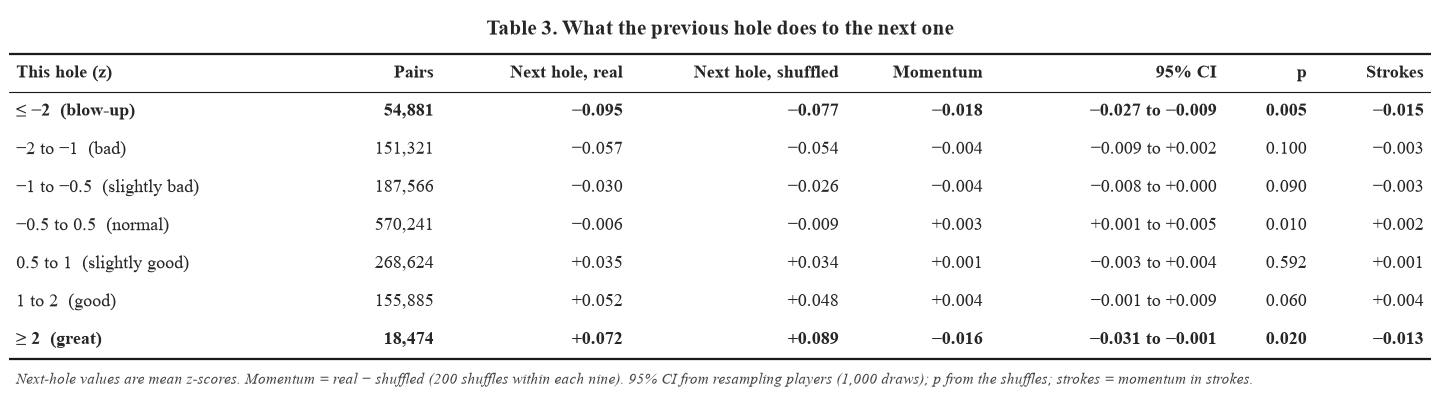

In [16]:
# ---- Table 3: the main result ----
T3 = pd.DataFrame({
    "This hole (z)": [f"{b}  ({nm})" for b, nm in zip(BUCKETS, NAMES)],
    "Pairs": [f"{v:,}" for v in RES["pairs"]],
    "Next hole, real": [sgn(v) for v in RES["real"]],
    "Next hole, shuffled": [sgn(v) for v in RES["shuffled"]],
    "Momentum": [sgn(v) for v in RES["momentum"]],
    "95% CI": [f"{sgn(l)} to {sgn(h)}" for l, h in zip(RES["lo"], RES["hi"])],
    "p": [f"{v:.3f}" for v in RES["p"]],
    "Strokes": [sgn(v) for v in RES["momentum (strokes)"]]})
print(T3.to_string(index=False))
save_table(T3, "table3_results", "Table 3. What the previous hole does to the next one", [3.3, 1.5, 2.1, 2.4, 1.6, 2.6, 1.0, 1.3],
           note="Next-hole values are mean z-scores. Momentum = real − shuffled (200 shuffles within each nine). "
                "95% CI from resampling players (1,000 draws); p from the shuffles; strokes = momentum in strokes.",
           bold_rows=(0, 6))

### Table 4. Robustness

The two key buckets (blow-up and great holes), re-estimated on subsets of the data. Each player
keeps the same skill and volatility baseline; only the holes included change.

                                Sample Rounds After blow-up           95% CI After great hole          95% CI 
              All D3 men (main result) 87,937       −0.018* −0.027 to −0.009          −0.016* −0.031 to −0.001
                        Season 2023-24 24,304        −0.010 −0.029 to +0.008           −0.020 −0.048 to +0.008
                        Season 2024-25 31,232       −0.024* −0.041 to −0.008           −0.016 −0.042 to +0.010
                        Season 2025-26 32,401       −0.019* −0.034 to −0.004           −0.014 −0.040 to +0.009
            Large fields (30+ players) 80,678       −0.018* −0.027 to −0.008           −0.015 −0.031 to +0.003
Players on national-championship teams 16,074        −0.010 −0.034 to +0.010           −0.017 −0.046 to +0.015
                         Everyone else 71,863       −0.020* −0.031 to −0.011           −0.017 −0.034 to +0.000


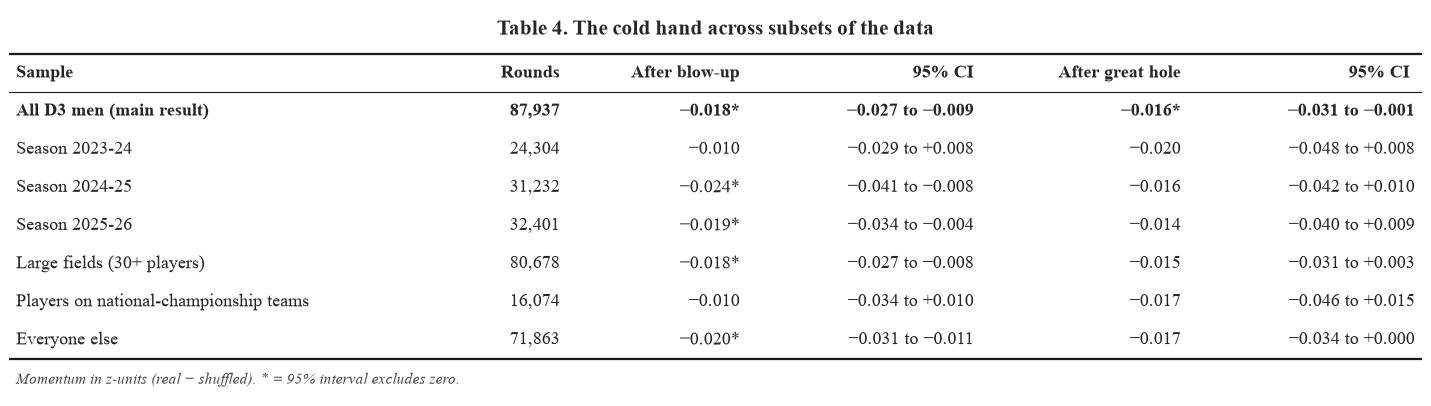

In [17]:
subsets = [("All D3 men (main result)", None)]
for s_ in sorted(R["season_label"].astype(str).unique()):
    subsets.append((f"Season {s_}", np.flatnonzero((R["season_label"].astype(str) == s_).to_numpy())))
subsets.append(("Large fields (30+ players)", np.flatnonzero((R["field_size"] >= 30).to_numpy())))
subsets.append(("Players on national-championship teams", np.flatnonzero(R["nat_team"].to_numpy())))
subsets.append(("Everyone else", np.flatnonzero(~R["nat_team"].to_numpy())))

rows = []
for name, rws in subsets:
    r_ = RES if rws is None else momentum(rws, n_shuffle=100, n_boot=500)
    n_rounds = len(R) if rws is None else len(rws)
    cold_, great_ = r_.iloc[0], r_.iloc[6]
    star = lambda q: "*" if (q["hi"] < 0 or q["lo"] > 0) else ""
    rows.append([name, f"{n_rounds:,}", f"{sgn(cold_['momentum'])}{star(cold_)}", f"{sgn(cold_['lo'])} to {sgn(cold_['hi'])}",
                 f"{sgn(great_['momentum'])}{star(great_)}", f"{sgn(great_['lo'])} to {sgn(great_['hi'])}"])
T4 = pd.DataFrame(rows, columns=["Sample", "Rounds", "After blow-up", "95% CI", "After great hole", "95% CI "])
print(T4.to_string(index=False))
save_table(T4, "table4_robustness", "Table 4. The cold hand across subsets of the data", [4.8, 1.4, 2.0, 2.6, 2.3, 2.6],
           note="Momentum in z-units (real − shuffled). * = 95% interval excludes zero.", bold_rows=(0,))

## 4. Poster text (numbers from this run)

In [18]:
cold, great = RES.iloc[0], RES.iloc[6]
print(f"""RESULTS
• Good holes follow good holes: after a blow-up hole the next hole averages z = {sgn(cold['real'], 2)}; after a great
  hole, z = {sgn(great['real'], 2)} (Figure 6, red).
• Most of that is the day: with hole order shuffled the same buckets give {sgn(cold['shuffled'], 2)} and {sgn(great['shuffled'], 2)}
  (Figure 6, grey).
• Cold hand: after a blow-up hole the next hole is {sgn(cold['momentum'])} SD worse than the day predicts
  (95% CI {sgn(cold['lo'])} to {sgn(cold['hi'])}; p = {cold['p']:.3f}), about {abs(cold['momentum (strokes)']):.3f} strokes (Figure 7, Table 3).
• No hot hand: after a great hole the next hole is no better than the day predicts ({sgn(great['momentum'])} SD,
  95% CI {sgn(great['lo'])} to {sgn(great['hi'])}).

CONCLUSION
Most of what looks like momentum on a scorecard is skill and the kind of day a player is having.
Beyond both, a blow-up hole still drags down the next one, while a great hole gives nothing extra:
a cold hand without a hot hand, the same asymmetry Elmore & Urbaczewski (2018) found on the PGA Tour.
The effect is small, but in golf bad holes linger and good holes don't.""")

RESULTS
• Good holes follow good holes: after a blow-up hole the next hole averages z = −0.10; after a great
  hole, z = +0.07 (Figure 6, red).
• Most of that is the day: with hole order shuffled the same buckets give −0.08 and +0.09
  (Figure 6, grey).
• Cold hand: after a blow-up hole the next hole is −0.018 SD worse than the day predicts
  (95% CI −0.027 to −0.009; p = 0.005), about 0.015 strokes (Figure 7, Table 3).
• No hot hand: after a great hole the next hole is no better than the day predicts (−0.016 SD,
  95% CI −0.031 to −0.001).

CONCLUSION
Most of what looks like momentum on a scorecard is skill and the kind of day a player is having.
Beyond both, a blow-up hole still drags down the next one, while a great hole gives nothing extra:
a cold hand without a hot hand, the same asymmetry Elmore & Urbaczewski (2018) found on the PGA Tour.
The effect is small, but in golf bad holes linger and good holes don't.
